In [3]:
# Arpit Huss (E23CSEU0554)

In [4]:
!pip install -q ucimlrepo

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.impute import SimpleImputer

from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    auc,
    roc_auc_score
)

sns.set_style("whitegrid")

In [5]:
dermatology = fetch_ucirepo(id=33)

X = dermatology.data.features.copy()
y = dermatology.data.targets.copy()

print("Dataset loaded successfully")
print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Dataset loaded successfully
Feature shape: (366, 34)
Target shape: (366, 1)


In [6]:
print("Features:")
display(X.head())

print("Target:")
display(y.head())

Features:


,erythema,scaling,definite-borders,itching,koebner phenomenon,polygonal papules,follicular papules,oral-mucosal involvement,knee elbow involvement,scalp involvement,...,focal hypergranulosis,disappearance of the granular layer,vacuolisation and damage of the basal layer,spongiosis,saw-tooth appearance of retes,follicular horn plug,perifollicular parakeratosis,inflammatory monoluclear infiltrate,band-like infiltrate,age
0,2,2,0,3,0,0,0,0,1,0,...,0,0,0,3,0,0,0,1,0,55.0
1,3,3,3,2,1,0,0,0,1,1,...,0,0,0,0,0,0,0,1,0,8.0
2,2,1,2,3,1,3,0,3,0,0,...,2,0,2,3,2,0,0,2,3,26.0
3,2,2,2,0,0,0,0,0,3,2,...,0,3,0,0,0,0,0,3,0,40.0
4,2,3,2,2,2,2,0,2,0,0,...,2,2,3,2,3,0,0,2,3,45.0


Target:


,class
0,2
1,1
2,3
3,1
4,3


In [8]:
target_column = y.columns[0]

df = X.copy()
df["class"] = y[target_column]

display(df.head())

,erythema,scaling,definite-borders,itching,koebner phenomenon,polygonal papules,follicular papules,oral-mucosal involvement,knee elbow involvement,scalp involvement,...,disappearance of the granular layer,vacuolisation and damage of the basal layer,spongiosis,saw-tooth appearance of retes,follicular horn plug,perifollicular parakeratosis,inflammatory monoluclear infiltrate,band-like infiltrate,age,class
0,2,2,0,3,0,0,0,0,1,0,...,0,0,3,0,0,0,1,0,55.0,2
1,3,3,3,2,1,0,0,0,1,1,...,0,0,0,0,0,0,1,0,8.0,1
2,2,1,2,3,1,3,0,3,0,0,...,0,2,3,2,0,0,2,3,26.0,3
3,2,2,2,0,0,0,0,0,3,2,...,3,0,0,0,0,0,3,0,40.0,1
4,2,3,2,2,2,2,0,2,0,0,...,2,3,2,3,0,0,2,3,45.0,3


In [9]:
print("Dataset shape:", df.shape)

print("\nData types:")
print(df.dtypes)

Dataset shape: (366, 35)

Data types:
erythema                                         int64
scaling                                          int64
definite-borders                                 int64
itching                                          int64
koebner phenomenon                               int64
polygonal papules                                int64
follicular papules                               int64
oral-mucosal involvement                         int64
knee elbow involvement                           int64
scalp involvement                                int64
family history                                   int64
melanin incontinence                             int64
eosinophils in the infiltrate                    int64
pnl infiltrate                                   int64
fibrosis of the papillary dermis                 int64
exocytosis                                       int64
acanthosis                                       int64
hyperkeratosis             

In [10]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
erythema,366.0,2.068306,0.664753,0.0,2.0,2.0,2.00,3.0
scaling,366.0,1.795082,0.701527,0.0,1.0,2.0,2.00,3.0
definite-borders,366.0,1.549180,0.907525,0.0,1.0,2.0,2.00,3.0
itching,366.0,1.366120,1.138299,0.0,0.0,1.0,2.00,3.0
koebner phenomenon,366.0,0.633880,0.908016,0.0,0.0,0.0,1.00,3.0
polygonal papules,366.0,0.448087,0.957327,0.0,0.0,0.0,0.00,3.0
follicular papules,366.0,0.166667,0.570588,0.0,0.0,0.0,0.00,3.0
oral-mucosal involvement,366.0,0.377049,0.834147,0.0,0.0,0.0,0.00,3.0
knee elbow involvement,366.0,0.614754,0.982979,0.0,0.0,0.0,1.00,3.0
scalp involvement,366.0,0.519126,0.905639,0.0,0.0,0.0,1.00,3.0


In [11]:
summary = pd.DataFrame({
    "Mean": df.mean(numeric_only=True),
    "Median": df.median(numeric_only=True),
    "Standard Deviation": df.std(numeric_only=True),
    "Minimum": df.min(numeric_only=True),
    "Maximum": df.max(numeric_only=True)
})

display(summary)

,Mean,Median,Standard Deviation,Minimum,Maximum
erythema,2.068306,2.0,0.664753,0.0,3.0
scaling,1.795082,2.0,0.701527,0.0,3.0
definite-borders,1.549180,2.0,0.907525,0.0,3.0
itching,1.366120,1.0,1.138299,0.0,3.0
koebner phenomenon,0.633880,0.0,0.908016,0.0,3.0
polygonal papules,0.448087,0.0,0.957327,0.0,3.0
follicular papules,0.166667,0.0,0.570588,0.0,3.0
oral-mucosal involvement,0.377049,0.0,0.834147,0.0,3.0
knee elbow involvement,0.614754,0.0,0.982979,0.0,3.0
scalp involvement,0.519126,0.0,0.905639,0.0,3.0


In [12]:
print("Missing values:")
print(df.isnull().sum())

print("\nTotal missing values:",
      df.isnull().sum().sum())

Missing values:
erythema                                       0
scaling                                        0
definite-borders                               0
itching                                        0
koebner phenomenon                             0
polygonal papules                              0
follicular papules                             0
oral-mucosal involvement                       0
knee elbow involvement                         0
scalp involvement                              0
family history                                 0
melanin incontinence                           0
eosinophils in the infiltrate                  0
pnl infiltrate                                 0
fibrosis of the papillary dermis               0
exocytosis                                     0
acanthosis                                     0
hyperkeratosis                                 0
parakeratosis                                  0
clubbing of the rete ridges                    0
elon

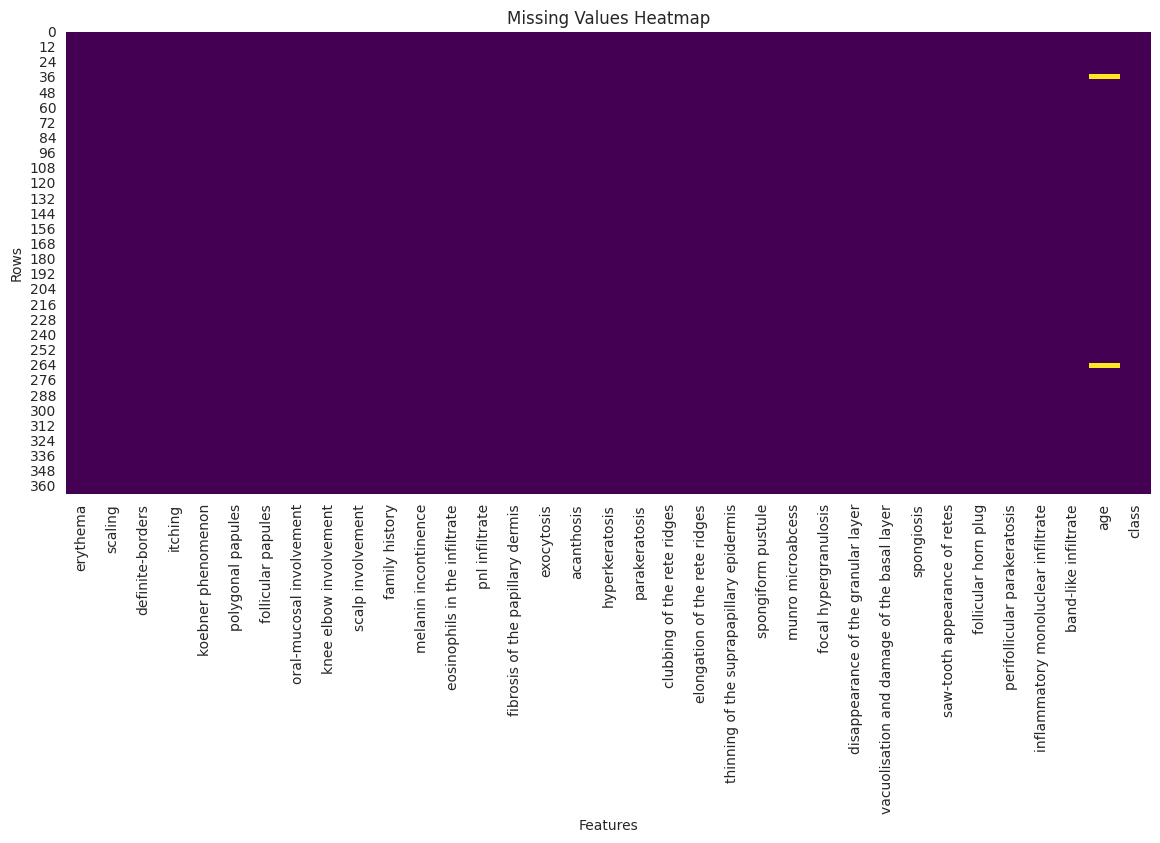

In [13]:
plt.figure(figsize=(14, 6))

sns.heatmap(
    df.isnull(),
    cbar=False,
    cmap="viridis"
)

plt.title("Missing Values Heatmap")
plt.xlabel("Features")
plt.ylabel("Rows")

plt.show()

In [14]:
print("Duplicate rows:",
      df.duplicated().sum())

Duplicate rows: 0


In [15]:
df = df.drop_duplicates()

print("Shape after removing duplicates:",
      df.shape)

Shape after removing duplicates: (366, 35)


In [16]:
X = df.drop("class", axis=1)
y = df["class"]

X = X.apply(
    pd.to_numeric,
    errors="coerce"
)

print("Features:", X.shape)
print("Target:", y.shape)

Features: (366, 34)
Target: (366,)


In [17]:
imputer = SimpleImputer(
    strategy="median"
)

X = pd.DataFrame(
    imputer.fit_transform(X),
    columns=X.columns,
    index=X.index
)

print(
    "Total missing values after imputation:",
    X.isnull().sum().sum()
)

Total missing values after imputation: 0


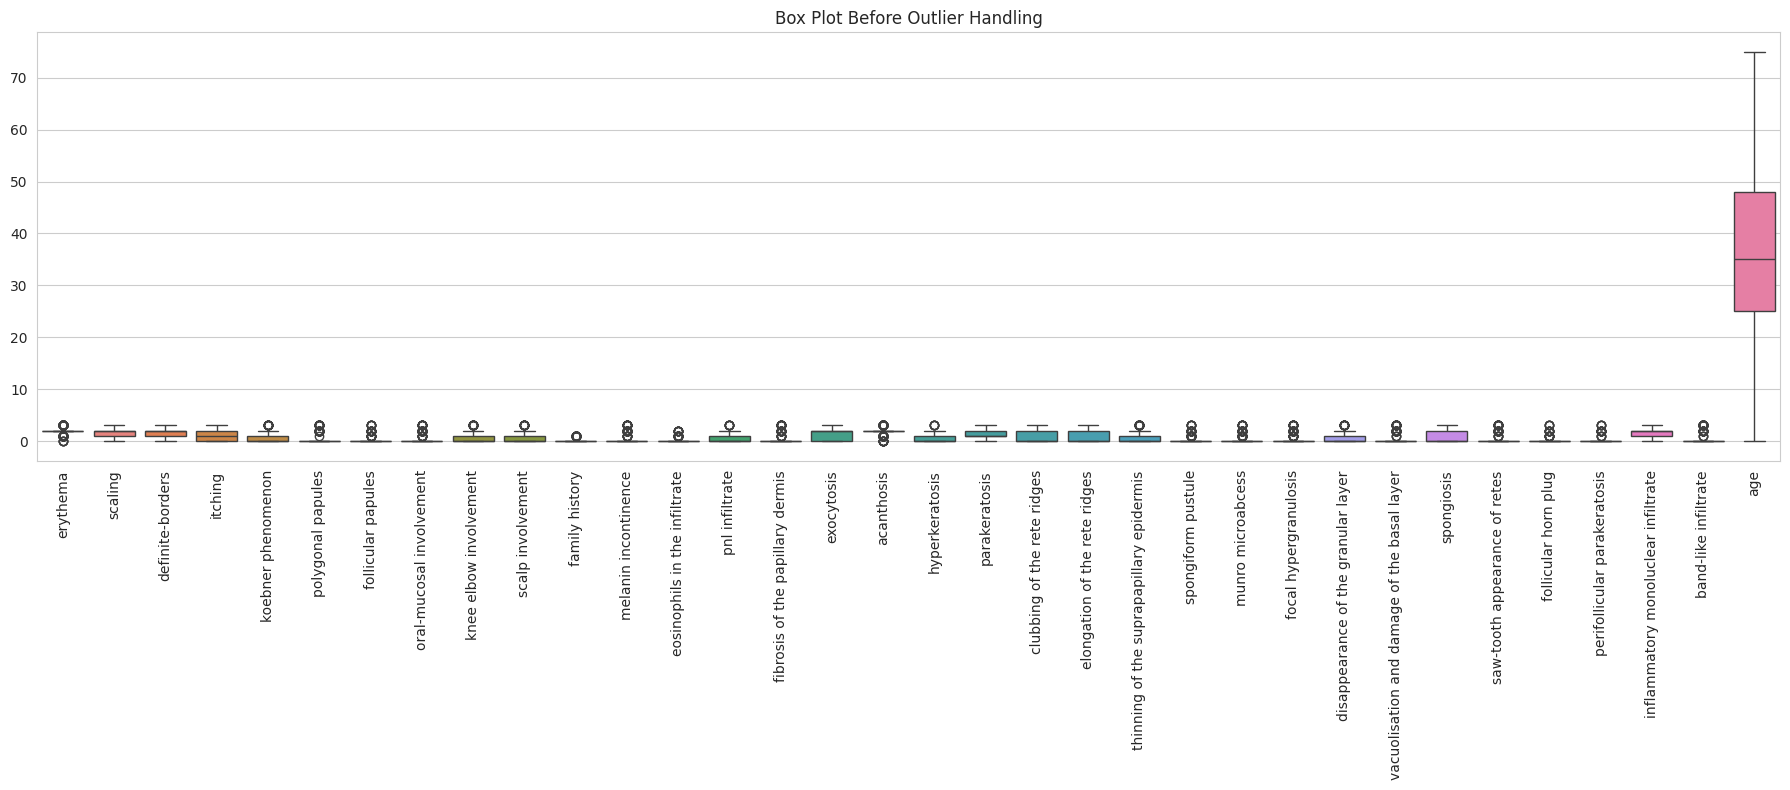

In [18]:
plt.figure(figsize=(18, 8))

sns.boxplot(data=X)

plt.title("Box Plot Before Outlier Handling")
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

In [19]:
outlier_counts = {}

for column in X.columns:

    Q1 = X[column].quantile(0.25)
    Q3 = X[column].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = (
        (X[column] < lower) |
        (X[column] > upper)
    ).sum()

    outlier_counts[column] = count

outlier_table = pd.DataFrame(
    outlier_counts.items(),
    columns=["Feature", "Outlier Count"]
)

display(outlier_table)

,Feature,Outlier Count
0,erythema,151
1,scaling,0
2,definite-borders,0
3,itching,0
4,koebner phenomenon,18
5,polygonal papules,69
6,follicular papules,33
7,oral-mucosal involvement,67
8,knee elbow involvement,23
9,scalp involvement,16


In [20]:
for column in X.columns:

    Q1 = X[column].quantile(0.25)
    Q3 = X[column].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    X[column] = X[column].clip(
        lower=lower,
        upper=upper
    )

print("Outliers handled using IQR clipping.")

Outliers handled using IQR clipping.


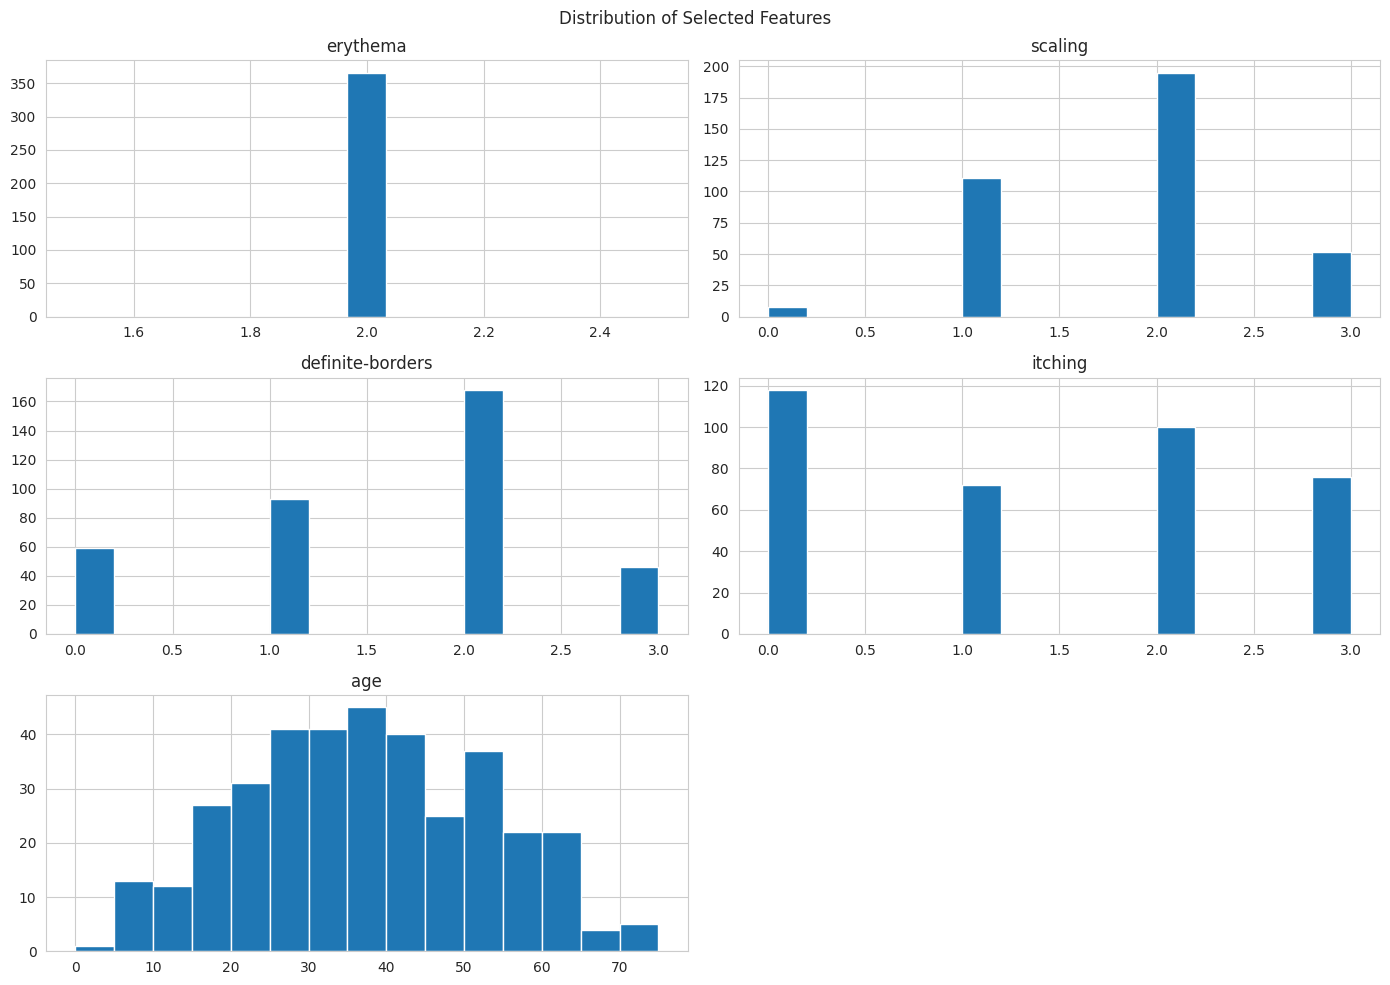

In [21]:
selected_features = [
    X.columns[0],
    X.columns[1],
    X.columns[2],
    X.columns[3],
    X.columns[-1]
]

X[selected_features].hist(
    figsize=(14, 10),
    bins=15
)

plt.suptitle("Distribution of Selected Features")

plt.tight_layout()
plt.show()

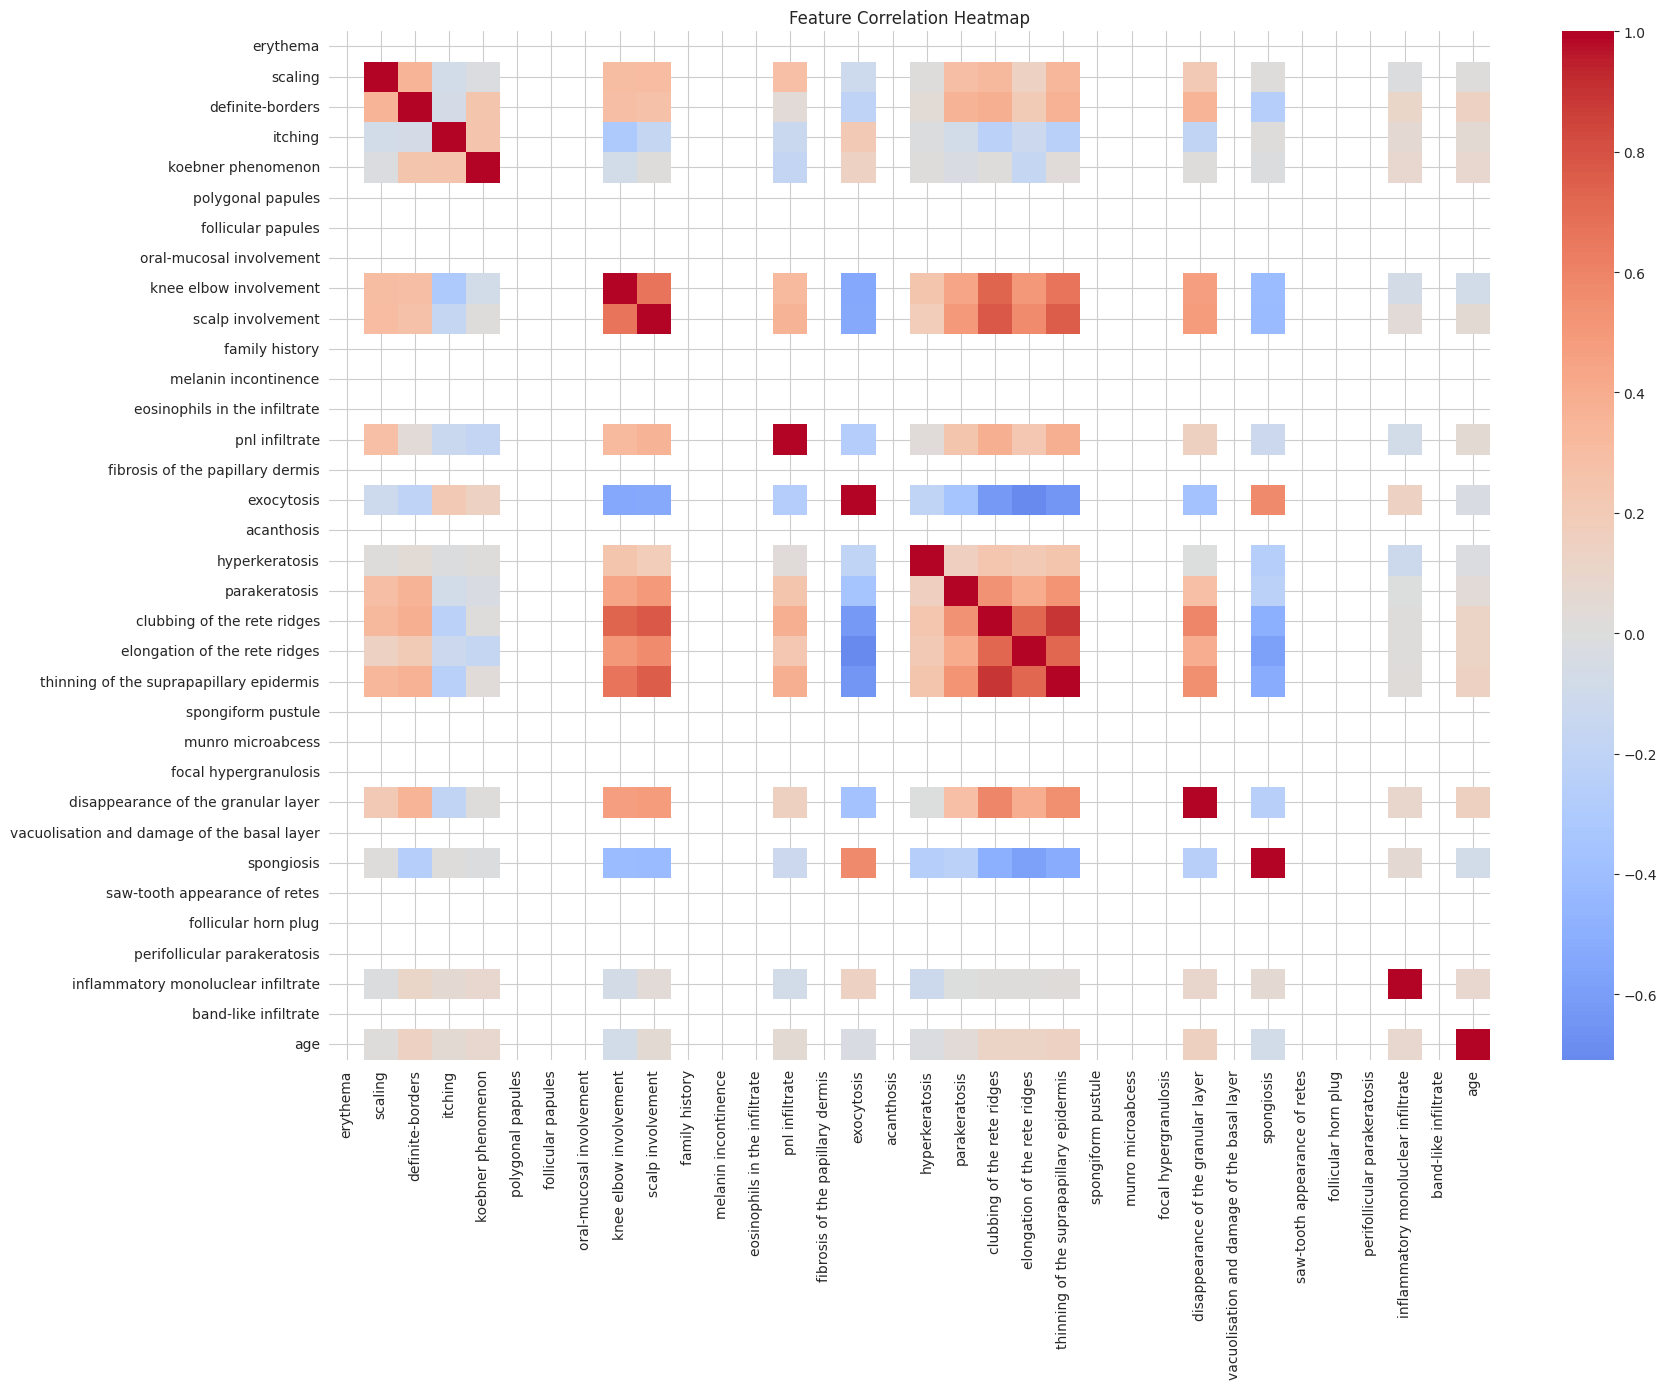

In [22]:
plt.figure(figsize=(18, 14))

sns.heatmap(
    X.corr(),
    cmap="coolwarm",
    center=0
)

plt.title("Feature Correlation Heatmap")

plt.tight_layout()
plt.show()

In [23]:
class_counts = y.value_counts().sort_index()

print("Class distribution:")
print(class_counts)

Class distribution:
class
1    112
2     61
3     72
4     49
5     52
6     20
Name: count, dtype: int64


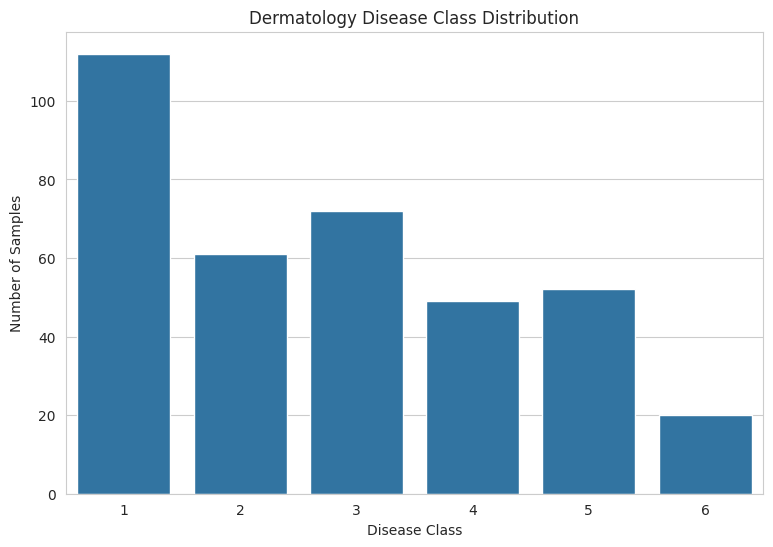

In [24]:
plt.figure(figsize=(9, 6))

sns.countplot(
    x=y,
    order=sorted(y.unique())
)

plt.title("Dermatology Disease Class Distribution")
plt.xlabel("Disease Class")
plt.ylabel("Number of Samples")

plt.show()

In [25]:
class_percentages = (
    y.value_counts(normalize=True)
    .sort_index()
    * 100
).round(2)

class_table = pd.DataFrame({
    "Samples": class_counts,
    "Percentage": class_percentages
})

display(class_table)

print("""
Class imbalance can affect model training.
A model may perform better on classes with more samples
and worse on classes with fewer samples.

Therefore, accuracy should not be considered alone.
Precision, recall, F1-score and AUC are also important.
""")

,Samples,Percentage
class,,
1,112,30.60
2,61,16.67
3,72,19.67
4,49,13.39
5,52,14.21
6,20,5.46



Class imbalance can affect model training.
A model may perform better on classes with more samples
and worse on classes with fewer samples.

Therefore, accuracy should not be considered alone.
Precision, recall, F1-score and AUC are also important.



In [26]:
y = y.astype(int)

print("Target classes:")
print(sorted(y.unique()))

Target classes:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]


In [27]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (292, 34)
Testing data: (74, 34)


In [28]:
print("Training class distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting class distribution:")
print(y_test.value_counts().sort_index())

Training class distribution:
class
1    89
2    49
3    57
4    39
5    42
6    16
Name: count, dtype: int64

Testing class distribution:
class
1    23
2    12
3    15
4    10
5    10
6     4
Name: count, dtype: int64


In [29]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Features standardized successfully.")

Features standardized successfully.


In [30]:
models = {

    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),

    "Logistic Regression": LogisticRegression(
        max_iter=2000
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42
    ),

    "SVM": SVC(
        kernel="rbf",
        probability=True,
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        random_state=42
    )
}

print("Models created successfully.")

Models created successfully.


In [31]:
trained_models = {}

for name, model in models.items():

    model.fit(
        X_train_scaled,
        y_train
    )

    trained_models[name] = model

    print(name, "trained successfully.")

KNN trained successfully.
Logistic Regression trained successfully.
Random Forest trained successfully.
SVM trained successfully.
Gradient Boosting trained successfully.


In [32]:
results = []

for name, model in trained_models.items():

    y_pred = model.predict(
        X_test_scaled
    )

    accuracy = accuracy_score(
        y_test,
        y_pred
    )

    precision = precision_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

results_df = pd.DataFrame(results)

display(results_df)

,Model,Accuracy,Precision,Recall,F1 Score
0,KNN,0.918919,0.922099,0.918919,0.914112
1,Logistic Regression,0.959459,0.958803,0.959459,0.958611
2,Random Forest,0.945946,0.947174,0.945946,0.946035
3,SVM,0.972973,0.972973,0.972973,0.972973
4,Gradient Boosting,0.932432,0.936937,0.932432,0.932159


In [33]:
for name, model in trained_models.items():

    y_pred = model.predict(
        X_test_scaled
    )

    print("\n" + "=" * 70)
    print(name)
    print("=" * 70)

    print(
        classification_report(
            y_test,
            y_pred,
            zero_division=0
        )
    )


KNN
              precision    recall  f1-score   support

           1       1.00      1.00      1.00        23
           2       0.88      0.58      0.70        12
           3       0.88      1.00      0.94        15
           4       0.75      0.90      0.82        10
           5       1.00      1.00      1.00        10
           6       1.00      1.00      1.00         4

    accuracy                           0.92        74
   macro avg       0.92      0.91      0.91        74
weighted avg       0.92      0.92      0.91        74


Logistic Regression
              precision    recall  f1-score   support

           1       1.00      1.00      1.00        23
           2       0.92      0.92      0.92        12
           3       0.94      1.00      0.97        15
           4       0.89      0.80      0.84        10
           5       1.00      1.00      1.00        10
           6       1.00      1.00      1.00         4

    accuracy                           0.96        

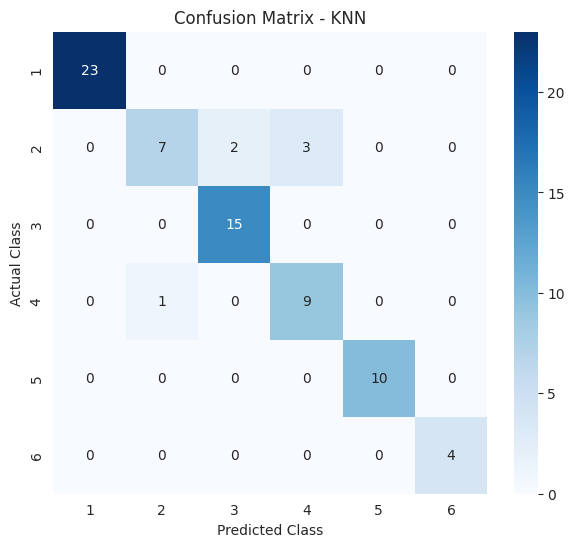

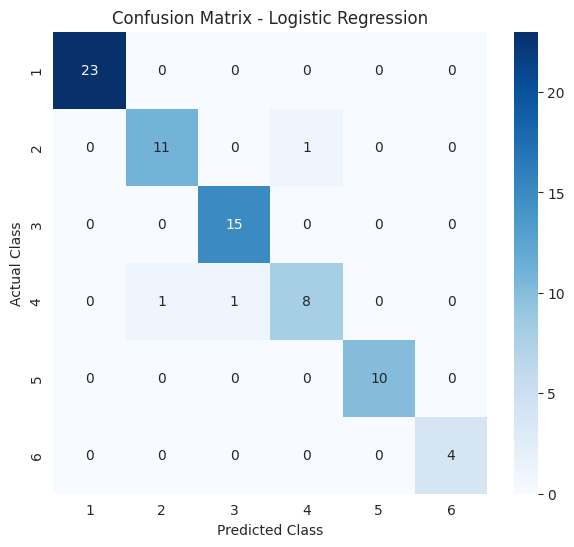

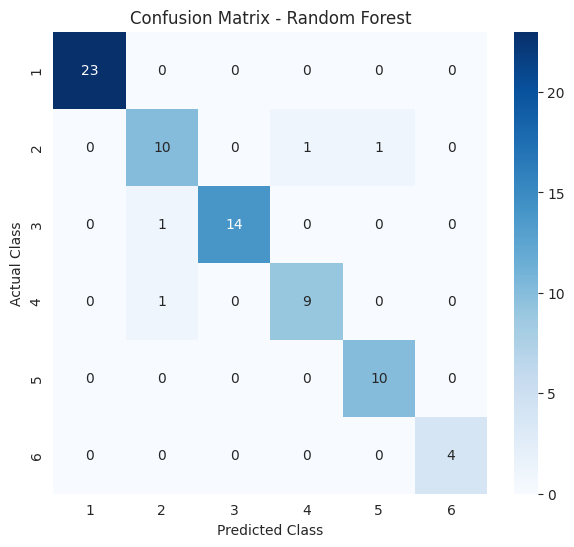

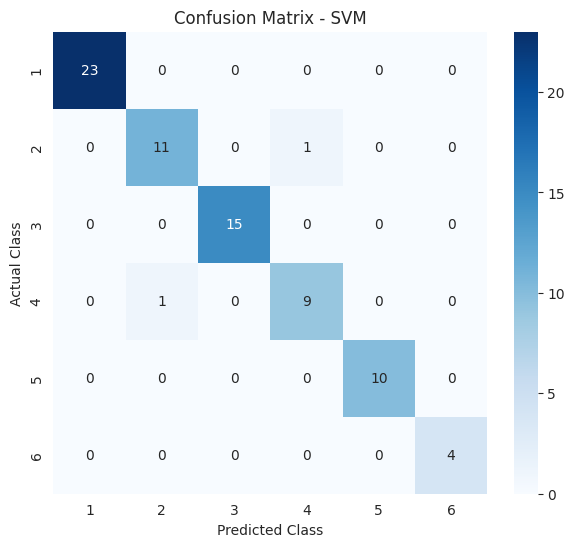

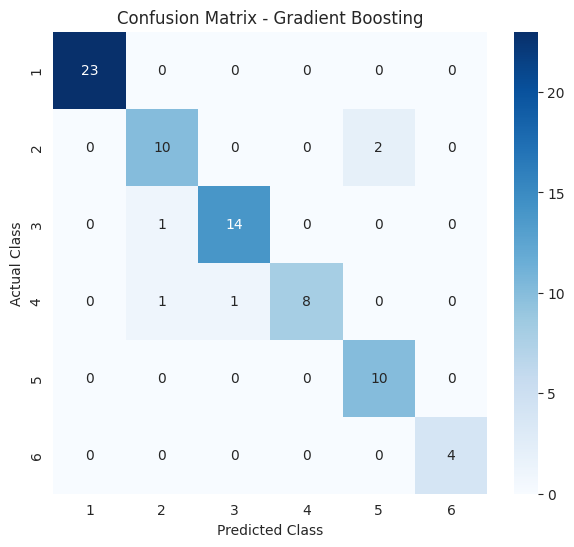

In [34]:
classes = sorted(y.unique())

for name, model in trained_models.items():

    y_pred = model.predict(
        X_test_scaled
    )

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=classes
    )

    plt.figure(figsize=(7, 6))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=classes,
        yticklabels=classes
    )

    plt.title(
        "Confusion Matrix - " + name
    )

    plt.xlabel("Predicted Class")
    plt.ylabel("Actual Class")

    plt.show()

In [35]:
y_test_binary = label_binarize(
    y_test,
    classes=classes
)

print("Classes:", classes)
print("Binary target shape:",
      y_test_binary.shape)

Classes: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]
Binary target shape: (74, 6)


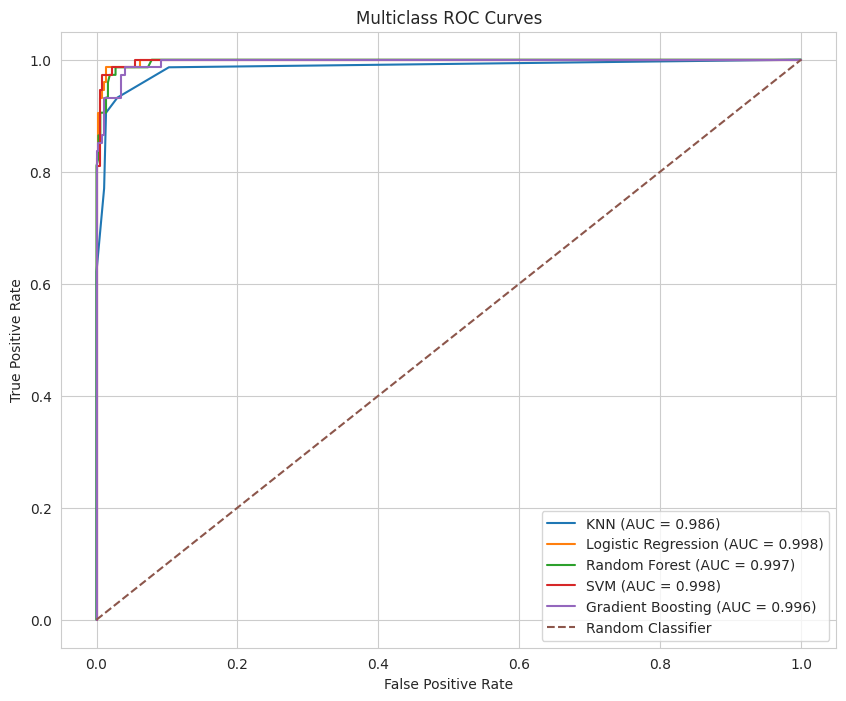

In [36]:
auc_results = []

plt.figure(figsize=(10, 8))

for name, model in trained_models.items():

    y_probability = model.predict_proba(
        X_test_scaled
    )

    macro_auc = roc_auc_score(
        y_test_binary,
        y_probability,
        multi_class="ovr",
        average="macro"
    )

    auc_results.append({
        "Model": name,
        "AUC": macro_auc
    })

    fpr, tpr, _ = roc_curve(
        y_test_binary.ravel(),
        y_probability.ravel()
    )

    roc_auc_value = auc(
        fpr,
        tpr
    )

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {roc_auc_value:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("Multiclass ROC Curves")

plt.legend()
plt.grid(True)

plt.show()

In [37]:
auc_df = pd.DataFrame(
    auc_results
)

print("AUC Scores:")
display(auc_df)

AUC Scores:


,Model,AUC
0,KNN,0.981371
1,Logistic Regression,0.997462
2,Random Forest,0.995747
3,SVM,0.996942
4,Gradient Boosting,0.993695


In [38]:
final_results = results_df.merge(
    auc_df,
    on="Model"
)

display(final_results)

,Model,Accuracy,Precision,Recall,F1 Score,AUC
0,KNN,0.918919,0.922099,0.918919,0.914112,0.981371
1,Logistic Regression,0.959459,0.958803,0.959459,0.958611,0.997462
2,Random Forest,0.945946,0.947174,0.945946,0.946035,0.995747
3,SVM,0.972973,0.972973,0.972973,0.972973,0.996942
4,Gradient Boosting,0.932432,0.936937,0.932432,0.932159,0.993695


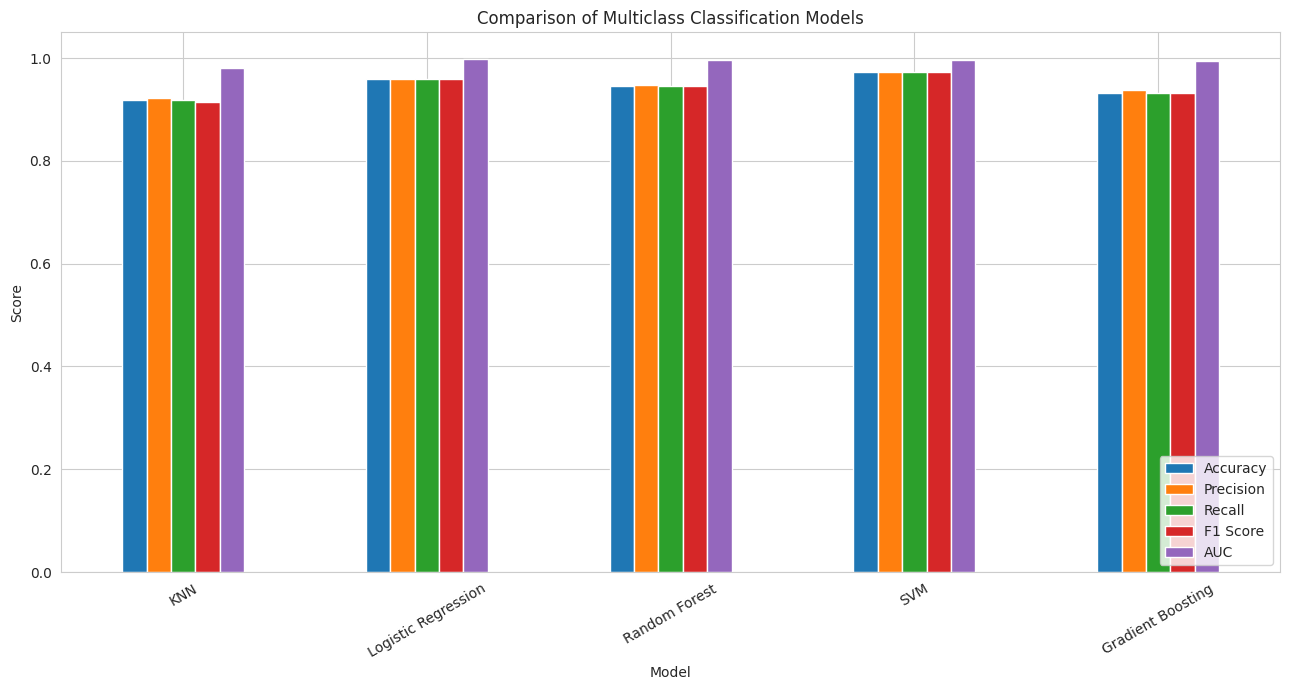

In [39]:
performance = final_results.set_index(
    "Model"
)[
    [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "AUC"
    ]
]

performance.plot(
    kind="bar",
    figsize=(13, 7)
)

plt.title(
    "Comparison of Multiclass Classification Models"
)

plt.xlabel("Model")
plt.ylabel("Score")

plt.ylim(0, 1.05)

plt.xticks(rotation=30)

plt.legend(
    loc="lower right"
)

plt.tight_layout()
plt.show()

In [40]:
for name, model in trained_models.items():

    y_pred = model.predict(
        X_test_scaled
    )

    report = classification_report(
        y_test,
        y_pred,
        labels=classes,
        target_names=[
            f"Class {c}"
            for c in classes
        ],
        output_dict=True,
        zero_division=0
    )

    report_df = pd.DataFrame(
        report
    ).transpose()

    print("\n" + "=" * 70)
    print(name)
    print("=" * 70)

    display(
        report_df.round(3)
    )


KNN


,precision,recall,f1-score,support
Class 1,1.000,1.000,1.000,23.000
Class 2,0.875,0.583,0.700,12.000
Class 3,0.882,1.000,0.938,15.000
Class 4,0.750,0.900,0.818,10.000
Class 5,1.000,1.000,1.000,10.000
Class 6,1.000,1.000,1.000,4.000
accuracy,0.919,0.919,0.919,0.919
macro avg,0.918,0.914,0.909,74.000
weighted avg,0.922,0.919,0.914,74.000



Logistic Regression


,precision,recall,f1-score,support
Class 1,1.000,1.000,1.000,23.000
Class 2,0.917,0.917,0.917,12.000
Class 3,0.938,1.000,0.968,15.000
Class 4,0.889,0.800,0.842,10.000
Class 5,1.000,1.000,1.000,10.000
Class 6,1.000,1.000,1.000,4.000
accuracy,0.959,0.959,0.959,0.959
macro avg,0.957,0.953,0.954,74.000
weighted avg,0.959,0.959,0.959,74.000



Random Forest


,precision,recall,f1-score,support
Class 1,1.000,1.000,1.000,23.000
Class 2,0.833,0.833,0.833,12.000
Class 3,1.000,0.933,0.966,15.000
Class 4,0.900,0.900,0.900,10.000
Class 5,0.909,1.000,0.952,10.000
Class 6,1.000,1.000,1.000,4.000
accuracy,0.946,0.946,0.946,0.946
macro avg,0.940,0.944,0.942,74.000
weighted avg,0.947,0.946,0.946,74.000



SVM


,precision,recall,f1-score,support
Class 1,1.000,1.000,1.000,23.000
Class 2,0.917,0.917,0.917,12.000
Class 3,1.000,1.000,1.000,15.000
Class 4,0.900,0.900,0.900,10.000
Class 5,1.000,1.000,1.000,10.000
Class 6,1.000,1.000,1.000,4.000
accuracy,0.973,0.973,0.973,0.973
macro avg,0.969,0.969,0.969,74.000
weighted avg,0.973,0.973,0.973,74.000



Gradient Boosting


,precision,recall,f1-score,support
Class 1,1.000,1.000,1.000,23.000
Class 2,0.833,0.833,0.833,12.000
Class 3,0.933,0.933,0.933,15.000
Class 4,1.000,0.800,0.889,10.000
Class 5,0.833,1.000,0.909,10.000
Class 6,1.000,1.000,1.000,4.000
accuracy,0.932,0.932,0.932,0.932
macro avg,0.933,0.928,0.927,74.000
weighted avg,0.937,0.932,0.932,74.000


In [41]:
print("""
FINAL INTERPRETATION

1. The Dermatology dataset contains six different disease classes.

2. The dataset was explored using summary statistics,
   missing-value analysis, duplicate checking and outlier analysis.

3. Missing numerical values were handled using median imputation.

4. Outliers were identified using the IQR method and handled
   using clipping.

5. Histograms, box plots and a correlation heatmap were used
   for exploratory data analysis.

6. The class distribution was visualized to identify possible
   class imbalance.

7. The target variable contains six disease classes.

8. The dataset was divided into 80% training data and 20%
   testing data using stratified sampling.

9. StandardScaler was used to standardize the numerical features.

10. Five multiclass classification algorithms were trained:
    KNN, Logistic Regression, Random Forest, SVM and
    Gradient Boosting.

11. Accuracy, precision, recall and F1-score were used
    to evaluate the models.

12. Classification reports provide precision, recall and
    F1-score for each disease class.

13. Confusion matrices show correct and incorrect predictions
    for every class.

14. Multiclass ROC curves and AUC scores were calculated
    using the One-vs-Rest approach.

15. In healthcare classification, accuracy should not be
    considered alone. Precision, recall, F1-score and AUC
    provide additional information about model performance.
""")


FINAL INTERPRETATION

1. The Dermatology dataset contains six different disease classes.

2. The dataset was explored using summary statistics,
   missing-value analysis, duplicate checking and outlier analysis.

3. Missing numerical values were handled using median imputation.

4. Outliers were identified using the IQR method and handled
   using clipping.

5. Histograms, box plots and a correlation heatmap were used
   for exploratory data analysis.

6. The class distribution was visualized to identify possible
   class imbalance.

7. The target variable contains six disease classes.

8. The dataset was divided into 80% training data and 20%
   testing data using stratified sampling.

9. StandardScaler was used to standardize the numerical features.

10. Five multiclass classification algorithms were trained:
    KNN, Logistic Regression, Random Forest, SVM and
    Gradient Boosting.

11. Accuracy, precision, recall and F1-score were used
    to evaluate the models.

12. Classificat